# 1. Import needed libraries

In [39]:
# Base: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset/

import os
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from glob import glob
#---------------------------------------
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
#---------------------------------------
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.preprocessing.image import ImageDataGenerator
#---------------------------------------
import warnings
warnings.filterwarnings("ignore")

# 2. Preprocessing

## 2.1 Load data

In [40]:
def train_df(tr_path):
    classes, class_paths = zip(*[(label, os.path.join(tr_path, label, image))
        for label in sorted(os.listdir(tr_path)) if os.path.isdir(os.path.join(tr_path, label))
        for image in sorted(os.listdir(os.path.join(tr_path, label)))]) # <-- ADICIONADO O SORTED AQUI TAMBÉM

    tr_df = pd.DataFrame({'Class Path': class_paths, 'Class': classes})
    return tr_df

In [41]:
def test_df(ts_path):
    classes, class_paths = zip(*[(label, os.path.join(ts_path, label, image))
        for label in sorted(os.listdir(ts_path)) if os.path.isdir(os.path.join(ts_path, label))
        for image in sorted(os.listdir(os.path.join(ts_path, label)))]) # <-- ADICIONADO O SORTED AQUI TAMBÉM

    ts_df = pd.DataFrame({'Class Path': class_paths, 'Class': classes})
    return ts_df

In [42]:
import os
import kagglehub

# 1. Descarrega automaticamente o dataset de classificação de MRI do Kaggle
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Dataset descarregado em:", path)

# 2. Define os caminhos corretos para a pasta de Treino e Teste com base no download
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

# 3. Executa as funções originais apontando para os novos caminhos dinâmicos
tr_df = train_df(train_dir)
ts_df = test_df(test_dir)

# Confirma se carregou corretamente
print(tr_df.head())

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset descarregado em: /kaggle/input/brain-tumor-mri-dataset
                                          Class Path   Class
0  /kaggle/input/brain-tumor-mri-dataset/Training...  glioma
1  /kaggle/input/brain-tumor-mri-dataset/Training...  glioma
2  /kaggle/input/brain-tumor-mri-dataset/Training...  glioma
3  /kaggle/input/brain-tumor-mri-dataset/Training...  glioma
4  /kaggle/input/brain-tumor-mri-dataset/Training...  glioma


In [43]:
tr_df = train_df(train_dir)
ts_df = test_df(test_dir)

In [7]:
tr_df

,Class Path,Class
0,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
1,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
2,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
3,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
4,/kaggle/input/brain-tumor-mri-dataset/Training...,glioma
...,...,...
5595,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
5596,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
5597,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary
5598,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary


In [44]:
ts_df

,Class Path,Class
0,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
1,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
2,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
3,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
4,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
...,...,...
1595,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
1596,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
1597,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
1598,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary


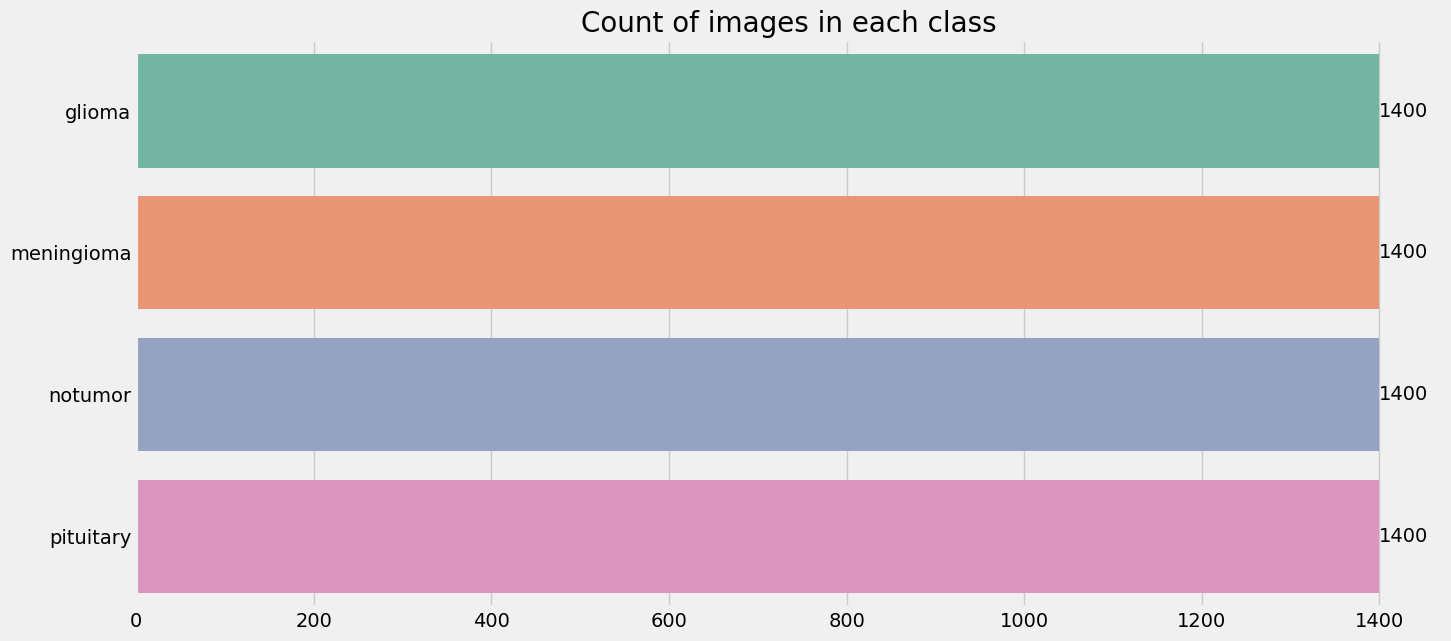

In [45]:
# Count of images in each class in train data
plt.figure(figsize=(15,7))

# Cria o gráfico de contagem horizontal com cores diferentes para cada barra
ax = sns.countplot(data=tr_df, y=tr_df['Class'], hue=tr_df['Class'], palette='Set2', legend=False)

plt.xlabel('')
plt.ylabel('')
plt.title('Count of images in each class', fontsize=20)
for container in ax.containers:
    ax.bar_label(container)
plt.show()



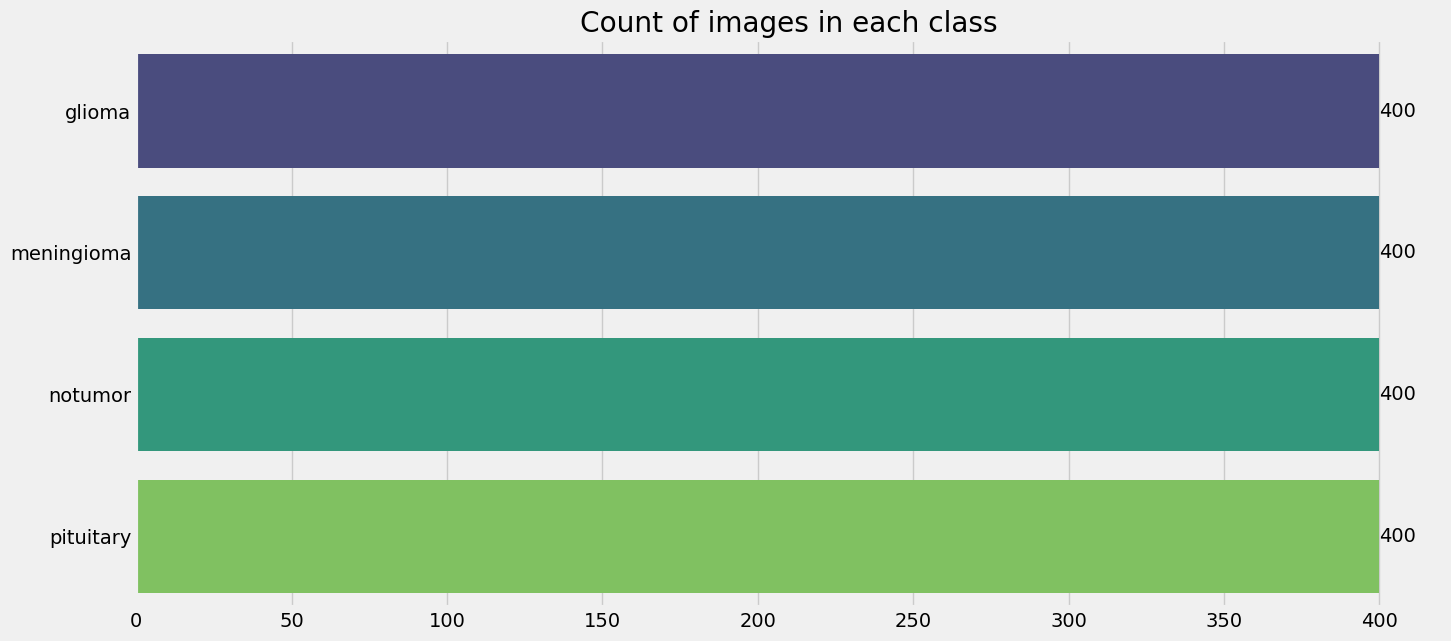

In [47]:
# Count each class in test data
plt.figure(figsize=(15, 7))
ax = sns.countplot(y=ts_df['Class'], palette='viridis')

ax.set(xlabel='', ylabel='', title='Count of images in each class')

# Itera por todos os contentores para adicionar os rótulos em todas as barras
for container in ax.containers:
    ax.bar_label(container)

plt.show()

## 2.2 Split data into train, test, valid

In [18]:
valid_df, ts_df = train_test_split(ts_df, train_size=0.5, random_state=20, stratify=ts_df['Class'])

In [19]:
valid_df

,Class Path,Class
1398,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
457,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
698,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
719,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma
908,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor
...,...,...
81,/kaggle/input/brain-tumor-mri-dataset/Testing/...,glioma
1372,/kaggle/input/brain-tumor-mri-dataset/Testing/...,pituitary
1192,/kaggle/input/brain-tumor-mri-dataset/Testing/...,notumor
533,/kaggle/input/brain-tumor-mri-dataset/Testing/...,meningioma


## 2.3 Data preprocessing

In [20]:
batch_size = 32
img_size = (299, 299)

_gen = ImageDataGenerator(rescale=1/255,
                          brightness_range=(0.8, 1.2))

ts_gen = ImageDataGenerator(rescale=1/255)


tr_gen = _gen.flow_from_dataframe(tr_df, x_col='Class Path',
                                  y_col='Class', batch_size=batch_size,
                                  target_size=img_size)

valid_gen = _gen.flow_from_dataframe(valid_df, x_col='Class Path',
                                     y_col='Class', batch_size=batch_size,
                                     target_size=img_size)

ts_gen = ts_gen.flow_from_dataframe(ts_df, x_col='Class Path',
                                  y_col='Class', batch_size=16,
                                  target_size=img_size, shuffle=False)

Found 5600 validated image filenames belonging to 4 classes.
Found 800 validated image filenames belonging to 4 classes.
Found 800 validated image filenames belonging to 4 classes.


## 2.4 Getting samples from data

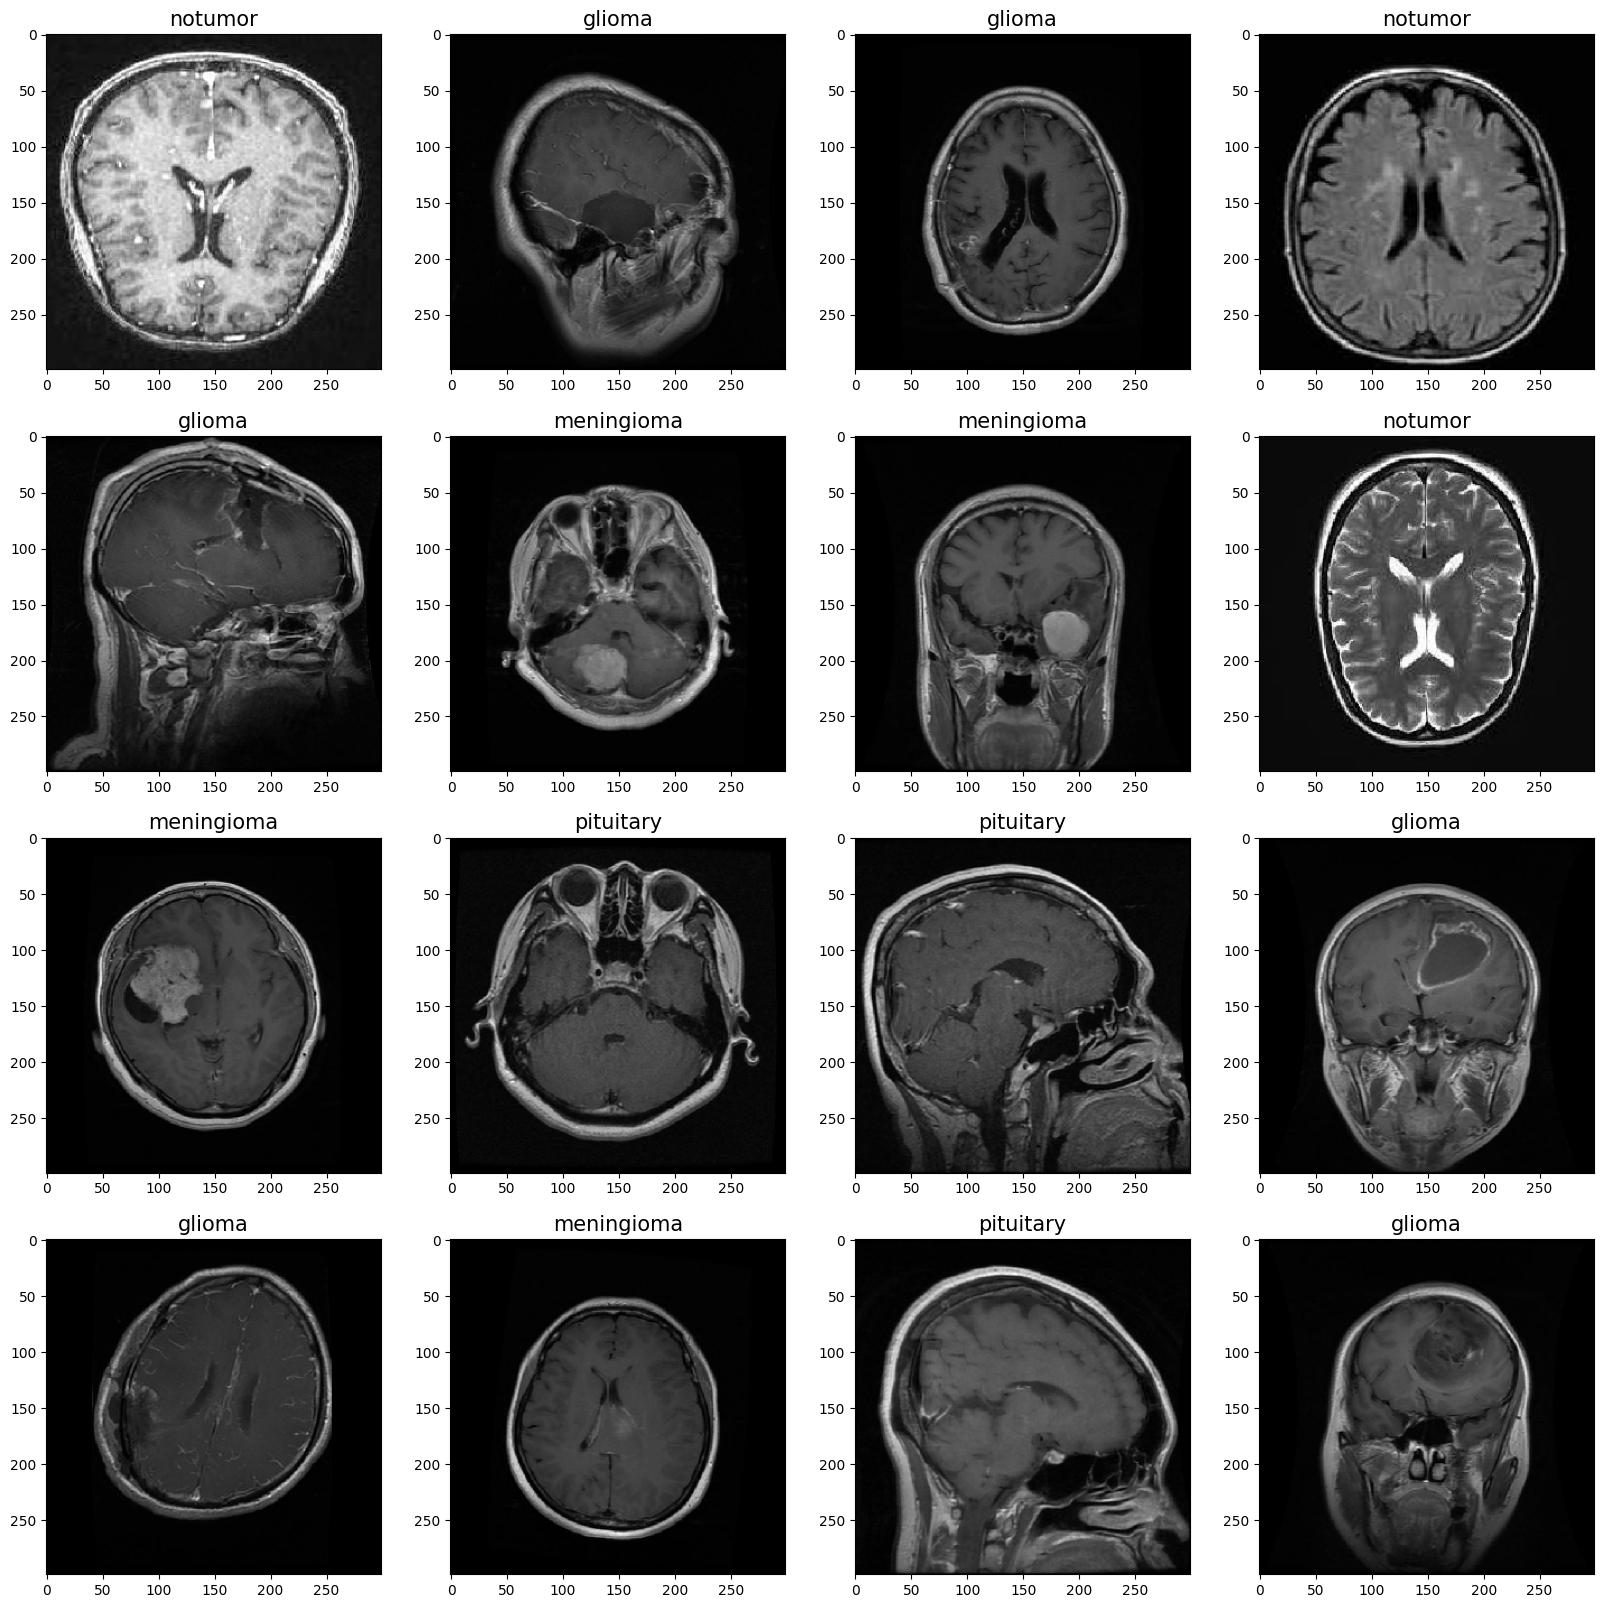

In [21]:
class_dict = tr_gen.class_indices
classes = list(class_dict.keys())
images, labels = next(ts_gen)

plt.figure(figsize=(20, 20))

for i, (image, label) in enumerate(zip(images, labels)):
    plt.subplot(4,4, i + 1)
    plt.imshow(image)
    class_name = classes[np.argmax(label)]
    plt.title(class_name, color='k', fontsize=15)

plt.show()

# 3. Building Deep Learning Model: Xception e Transfer Learning

In [22]:
img_shape=(299,299,3)
base_model = tf.keras.applications.Xception(include_top= False, weights= "imagenet",
                            input_shape= img_shape, pooling= 'max')

# for layer in base_model.layers:
#     layer.trainable = False

model = Sequential([
    base_model,
    Flatten(),
    Dropout(rate= 0.3),
    Dense(128, activation= 'relu'),
    Dropout(rate= 0.25),
    Dense(4, activation= 'softmax')
])

# Adamax e Categorical Crossentropy:
model.compile(Adamax(learning_rate= 0.001),
              loss= 'categorical_crossentropy',
              metrics= ['accuracy',
                        Precision(),
                        Recall()])

model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xception (Functional)           │ (None, 2048)           │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,124,268 (80.58 MB)

 Trainable params: 21,069,740 (80.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

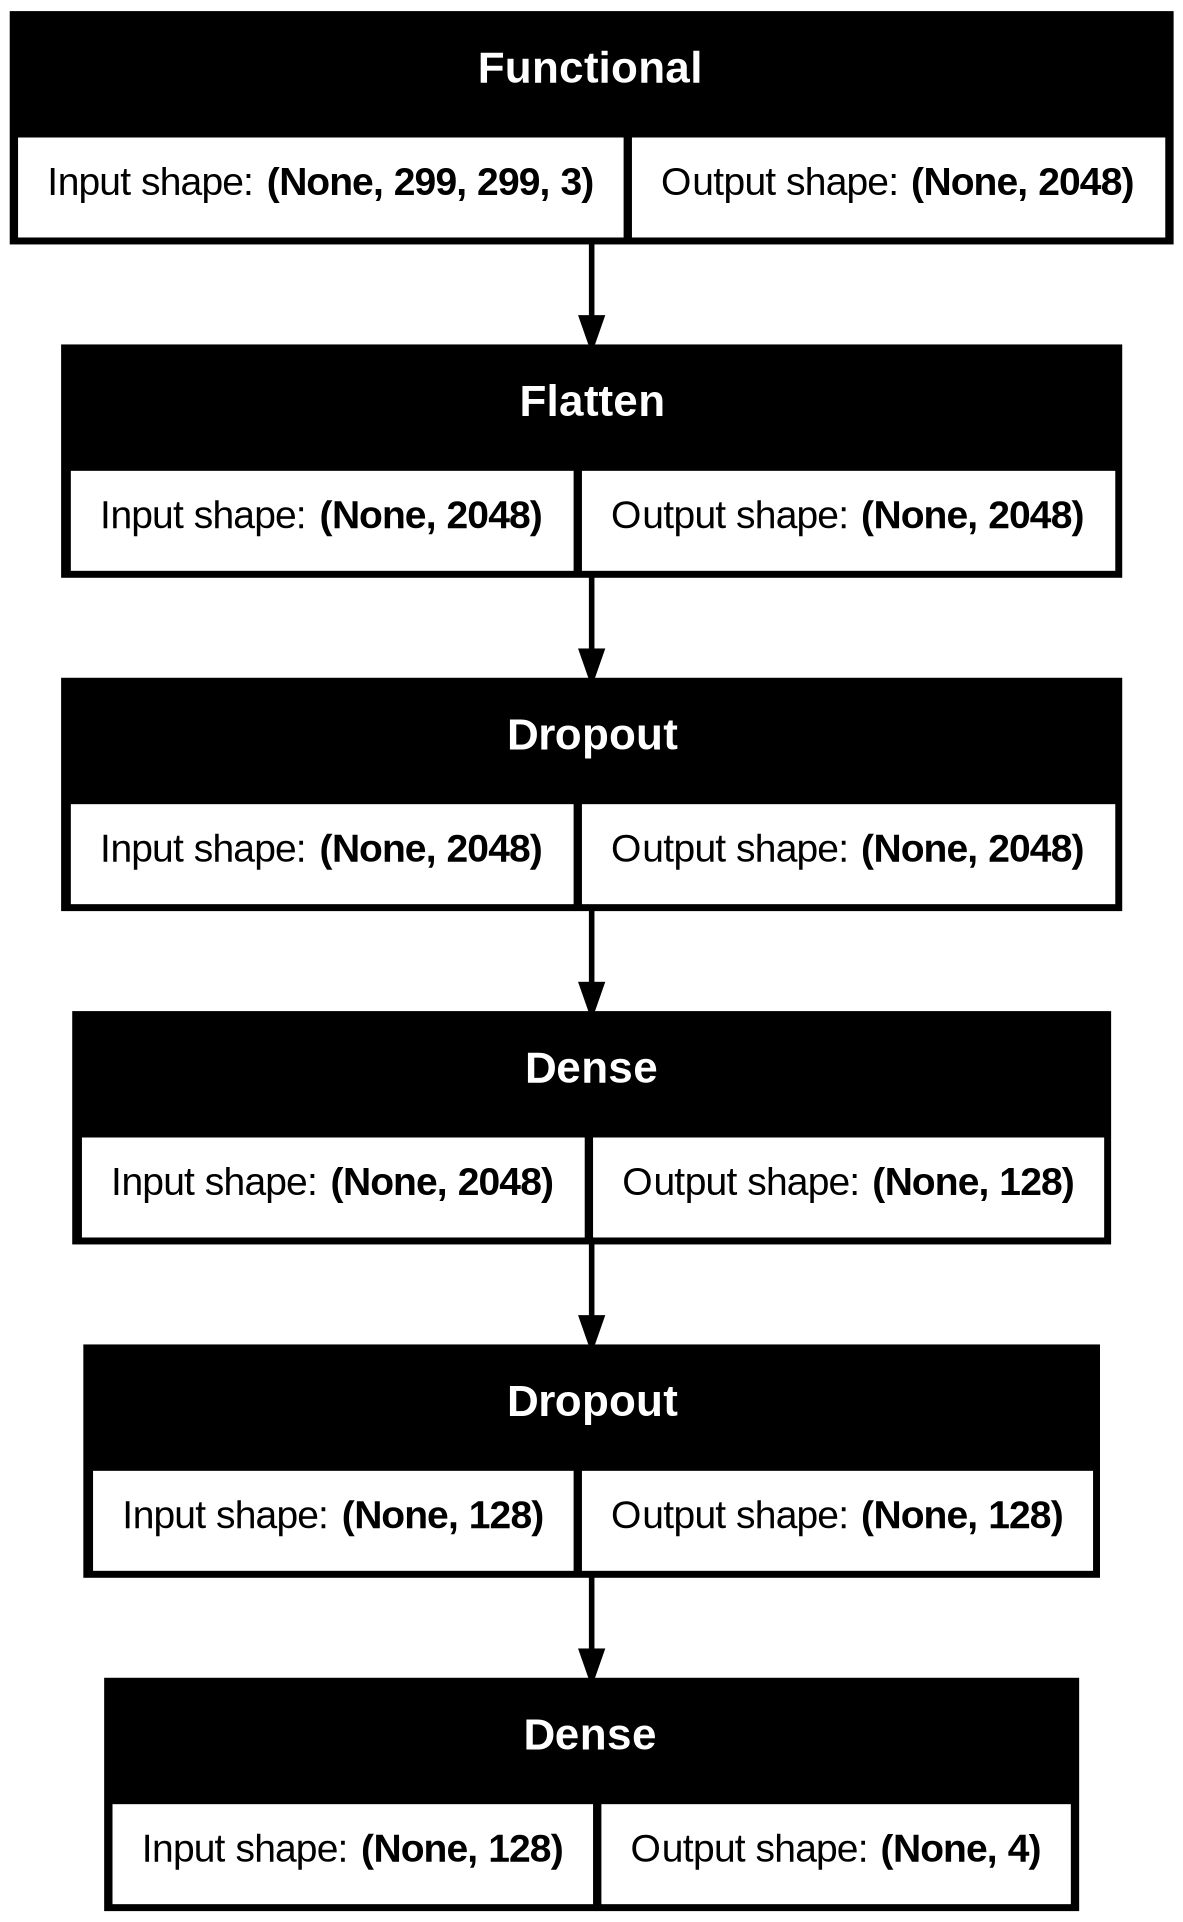

In [23]:
tf.keras.utils.plot_model(model, show_shapes=True)

# 4. Training

In [24]:
hist = model.fit(tr_gen,
                 epochs=10,
                 validation_data=valid_gen,
                 shuffle= False)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 277s 916ms/step - accuracy: 0.8954 - loss: 0.3070 - precision: 0.9213 - recall: 0.8700 - val_accuracy: 0.7663 - val_loss: 0.9028 - val_precision: 0.7735 - val_recall: 0.7600
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 154s 881ms/step - accuracy: 0.9814 - loss: 0.0553 - precision: 0.9826 - recall: 0.9804 - val_accuracy: 0.8775 - val_loss: 0.5182 - val_precision: 0.8837 - val_recall: 0.8737
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 154s 880ms/step - accuracy: 0.9889 - loss: 0.0347 - precision: 0.9893 - recall: 0.9884 - val_accuracy: 0.9150 - val_loss: 0.5101 - val_precision: 0.9171 - val_recall: 0.9125
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 154s 876ms/step - accuracy: 0.9918 - loss: 0.0258 - precision: 0.9927 - recall: 0.9914 - val_accuracy: 0.9538 - val_loss: 0.2361 - val_precision: 0.9573 - val_recall: 0.9525
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 154s 878ms/step - accuracy: 0.9987 - loss: 0.0042 - precision: 0.9989 - recall: 0.9987 - val_accuracy: 0

In [25]:
hist.history.keys()

dict_keys(['accuracy', 'loss', 'precision', 'recall', 'val_accuracy', 'val_loss', 'val_precision', 'val_recall'])

## 4.1 Visualize model performance

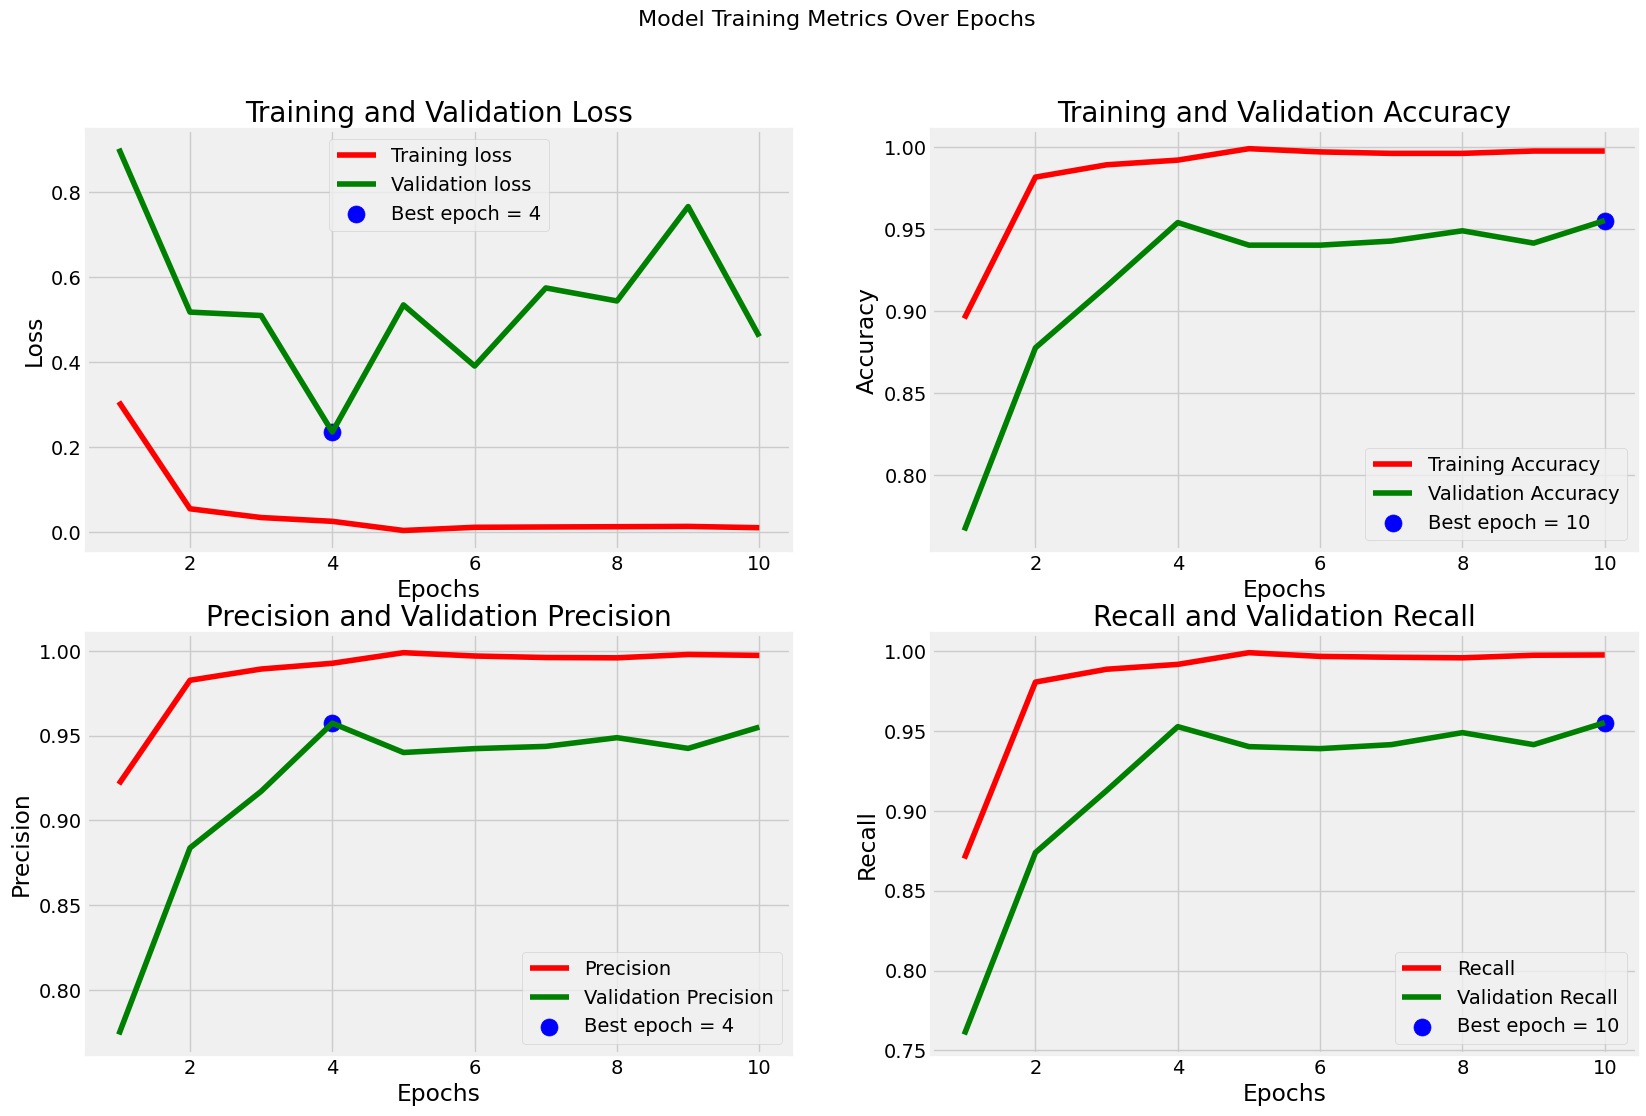

In [26]:
tr_acc = hist.history['accuracy']
tr_loss = hist.history['loss']
tr_per = hist.history['precision']
tr_recall = hist.history['recall']
val_acc = hist.history['val_accuracy']
val_loss = hist.history['val_loss']
val_per = hist.history['val_precision']
val_recall = hist.history['val_recall']

index_loss = np.argmin(val_loss)
val_lowest = val_loss[index_loss]
index_acc = np.argmax(val_acc)
acc_highest = val_acc[index_acc]
index_precision = np.argmax(val_per)
per_highest = val_per[index_precision]
index_recall = np.argmax(val_recall)
recall_highest = val_recall[index_recall]

Epochs = [i + 1 for i in range(len(tr_acc))]
loss_label = f'Best epoch = {str(index_loss + 1)}'
acc_label = f'Best epoch = {str(index_acc + 1)}'
per_label = f'Best epoch = {str(index_precision + 1)}'
recall_label = f'Best epoch = {str(index_recall + 1)}'


plt.figure(figsize=(20, 12))
plt.style.use('fivethirtyeight')


plt.subplot(2, 2, 1)
plt.plot(Epochs, tr_loss, 'r', label='Training loss')
plt.plot(Epochs, val_loss, 'g', label='Validation loss')
plt.scatter(index_loss + 1, val_lowest, s=150, c='blue', label=loss_label)
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(Epochs, tr_acc, 'r', label='Training Accuracy')
plt.plot(Epochs, val_acc, 'g', label='Validation Accuracy')
plt.scatter(index_acc + 1, acc_highest, s=150, c='blue', label=acc_label)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(Epochs, tr_per, 'r', label='Precision')
plt.plot(Epochs, val_per, 'g', label='Validation Precision')
plt.scatter(index_precision + 1, per_highest, s=150, c='blue', label=per_label)
plt.title('Precision and Validation Precision')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(Epochs, tr_recall, 'r', label='Recall')
plt.plot(Epochs, val_recall, 'g', label='Validation Recall')
plt.scatter(index_recall + 1, recall_highest, s=150, c='blue', label=recall_label)
plt.title('Recall and Validation Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)

plt.suptitle('Model Training Metrics Over Epochs', fontsize=16)
plt.show()

# 5. Testing and Evaluation

## 5.1 Evaluate

In [27]:
train_score = model.evaluate(tr_gen, verbose=1)
valid_score = model.evaluate(valid_gen, verbose=1)
test_score = model.evaluate(ts_gen, verbose=1)

print(f"Train Loss: {train_score[0]:.4f}")
print(f"Train Accuracy: {train_score[1]*100:.2f}%")
print('-' * 20)
print(f"Validation Loss: {valid_score[0]:.4f}")
print(f"Validation Accuracy: {valid_score[1]*100:.2f}%")
print('-' * 20)
print(f"Test Loss: {test_score[0]:.4f}")
print(f"Test Accuracy: {test_score[1]*100:.2f}%")


175/175 ━━━━━━━━━━━━━━━━━━━━ 43s 246ms/step - accuracy: 0.9996 - loss: 0.0023 - precision: 0.9996 - recall: 0.9996
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 248ms/step - accuracy: 0.9538 - loss: 0.4669 - precision: 0.9538 - recall: 0.9538
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 145ms/step - accuracy: 0.9513 - loss: 0.4799 - precision: 0.9513 - recall: 0.9513
Train Loss: 0.0023
Train Accuracy: 99.96%
--------------------
Validation Loss: 0.4669
Validation Accuracy: 95.38%
--------------------
Test Loss: 0.4799
Test Accuracy: 95.13%


In [28]:
preds = model.predict(ts_gen)
y_pred = np.argmax(preds, axis=1)

50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 115ms/step


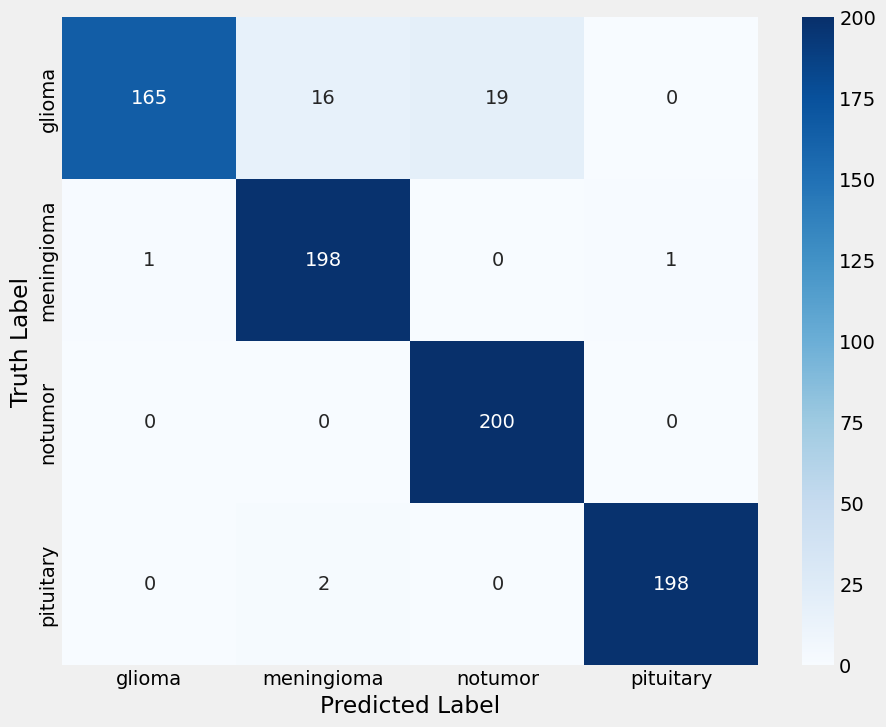

In [29]:
cm = confusion_matrix(ts_gen.classes, y_pred)
labels = list(class_dict.keys())
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('Truth Label')
plt.show()

In [30]:
clr = classification_report(ts_gen.classes, y_pred)
print(clr)

              precision    recall  f1-score   support

           0       0.99      0.82      0.90       200
           1       0.92      0.99      0.95       200
           2       0.91      1.00      0.95       200
           3       0.99      0.99      0.99       200

    accuracy                           0.95       800
   macro avg       0.95      0.95      0.95       800
weighted avg       0.95      0.95      0.95       800



## 5.2 Testing

In [31]:
print(ts_df['Class'].unique())

['notumor' 'glioma' 'meningioma' 'pituitary']


In [32]:
def predict(img_path):
    import numpy as np
    import matplotlib.pyplot as plt
    from PIL import Image

    # MUDA ISTO (remove a lista manual e usa as chaves do dicionário do gerador):
    label = list(class_dict.keys())

    plt.figure(figsize=(12, 12))
    img = Image.open(img_path).convert('RGB')
    resized_img = img.resize((299, 299))
    img = np.asarray(resized_img)
    img = np.expand_dims(img, axis=0)
    img = img / 255

    predictions = model.predict(img)
    probs = list(predictions[0])

    plt.subplot(2, 1, 1)
    plt.imshow(resized_img)
    plt.subplot(2, 1, 2)
    bars = plt.barh(label, probs)
    plt.xlabel('Probability', fontsize=15)
    ax = plt.gca()
    ax.bar_label(bars, fmt='%.2f')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step


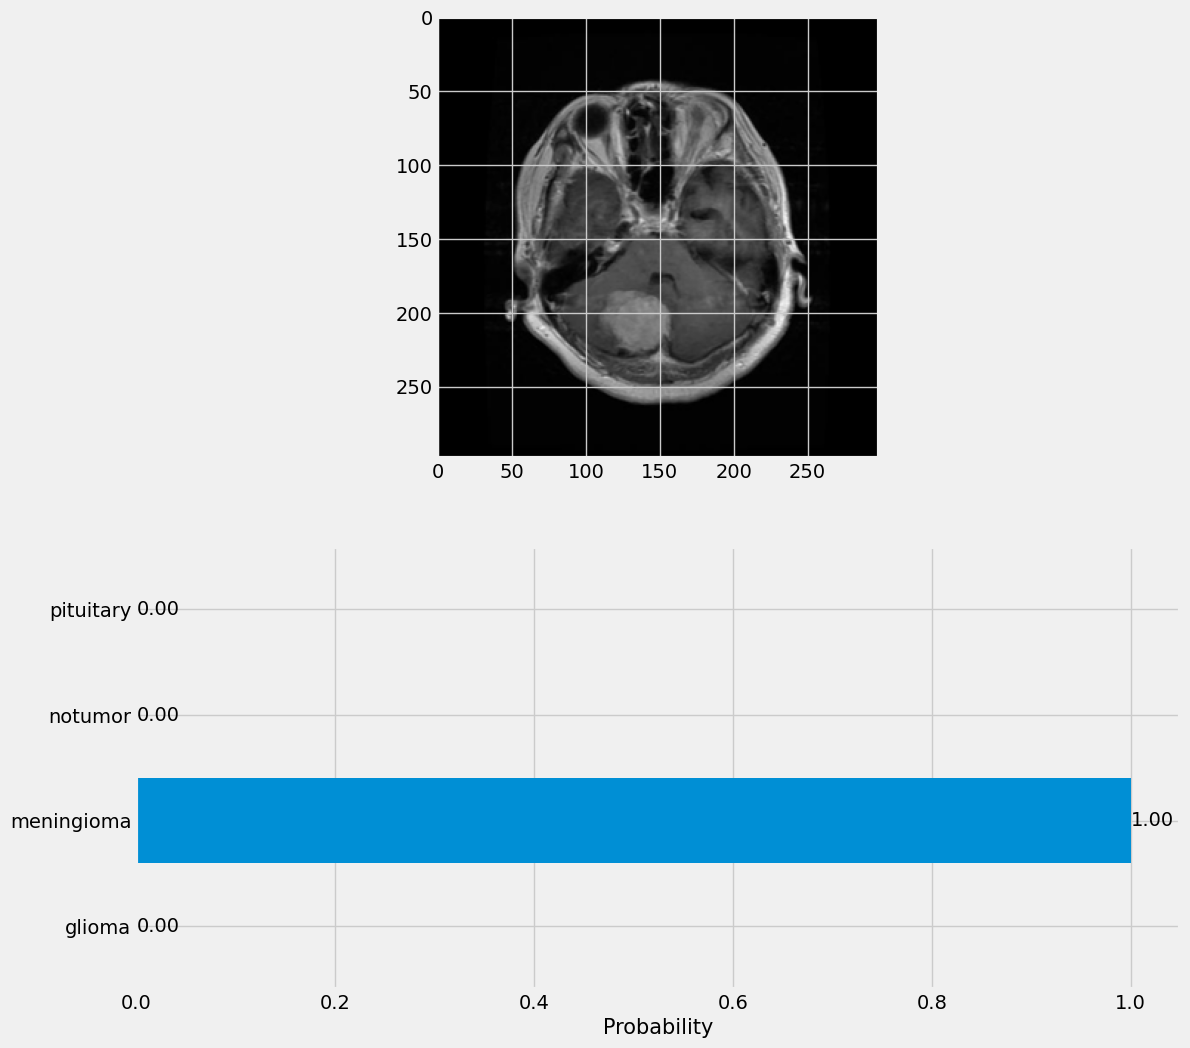

In [33]:
meningioma_path = ts_df[ts_df['Class'] == 'meningioma']['Class Path'].iloc[0]
predict(meningioma_path)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


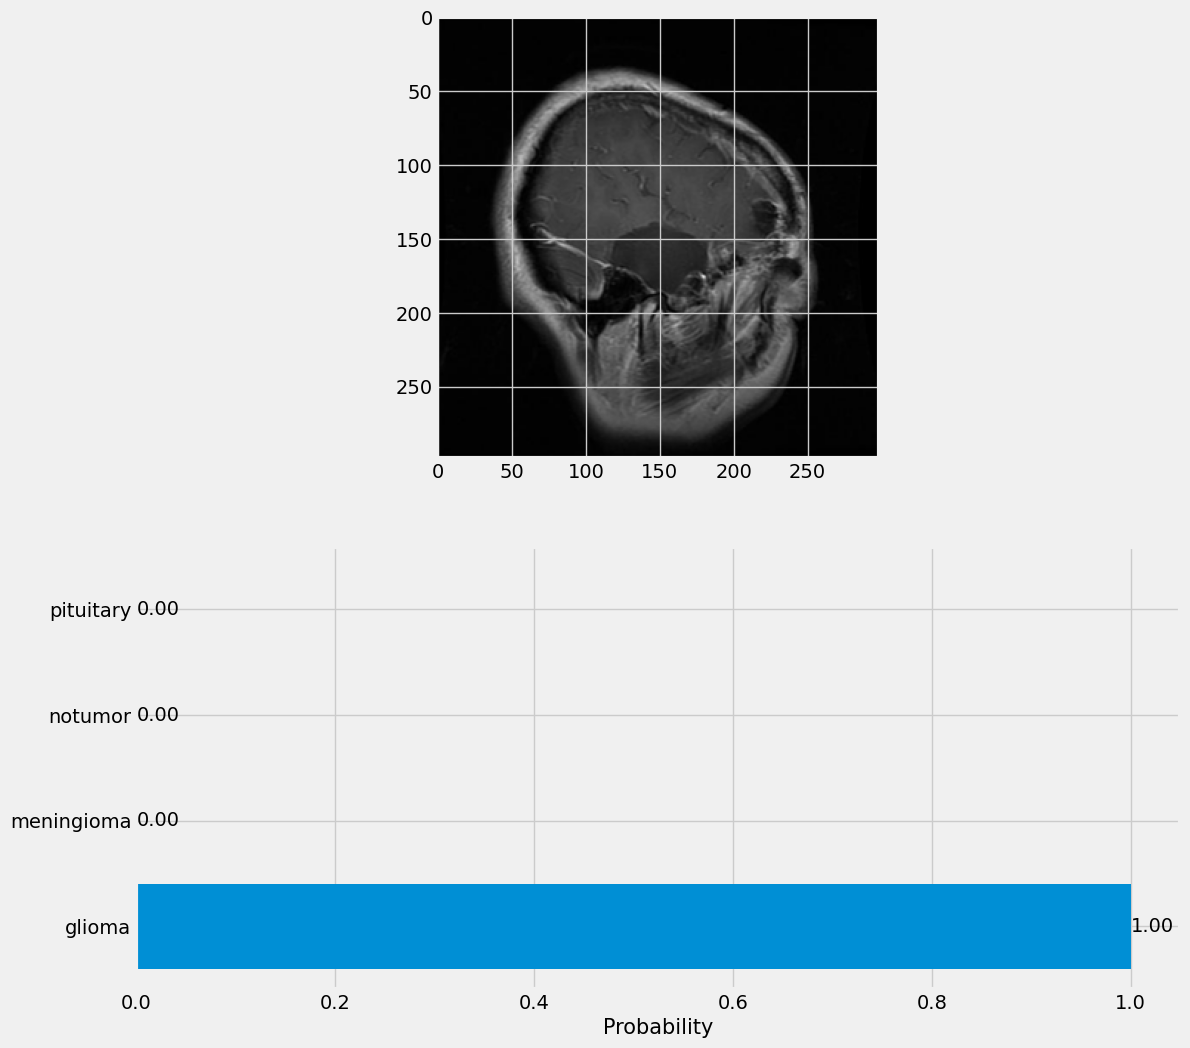

In [34]:
glioma_path = ts_df[ts_df['Class'] == 'glioma']['Class Path'].iloc[0]
predict(glioma_path)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


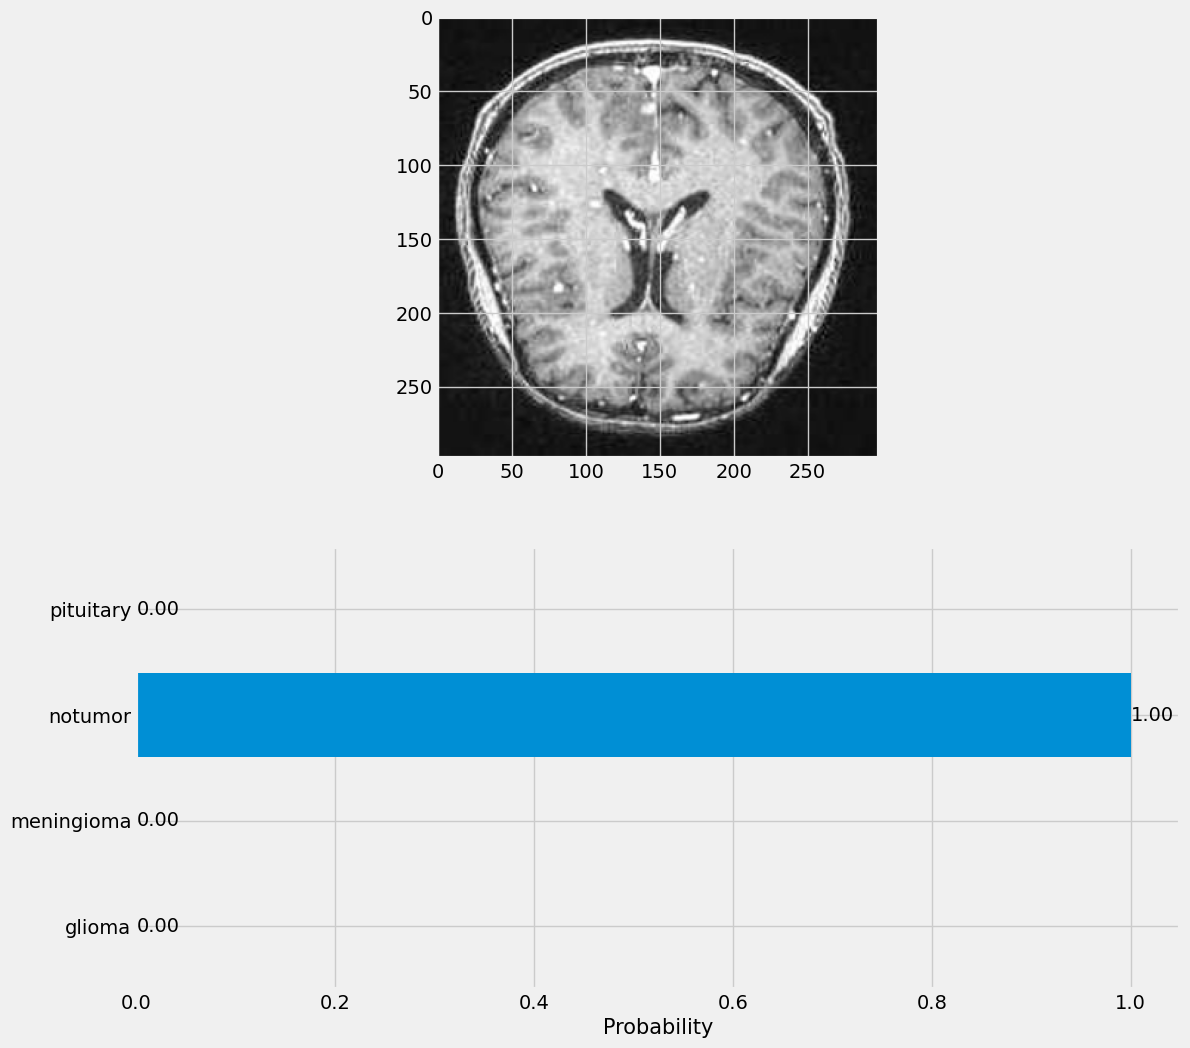

In [35]:
notumor_path = ts_df[ts_df['Class'] == 'notumor']['Class Path'].iloc[0]
predict(notumor_path)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


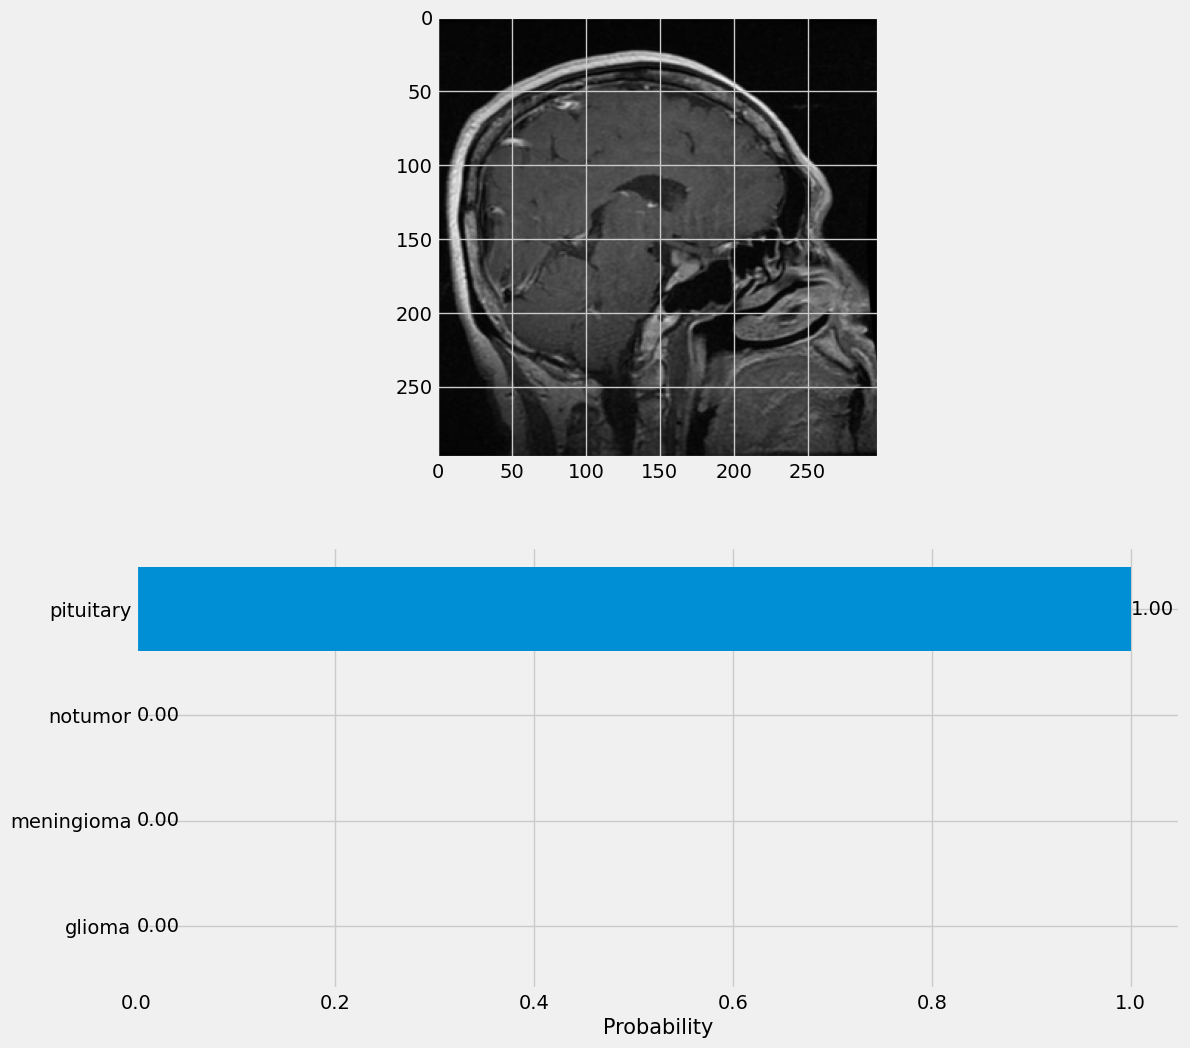

In [36]:
pituitary_path = ts_df[ts_df['Class'] == 'pituitary']['Class Path'].iloc[1]
predict(pituitary_path)